# NPO13 — Earnings of Employed Non-Progressors: Exploratory Analysis

**Source:** CSO table NPO13 via [data.gov.ie](https://data.gov.ie/dataset/npo13-earnings-of-employed-non-progressors) (CC-BY-4.0).

**Who:** first-year new entrants to Irish higher education who did **not progress** to second year (cohorts 2018–2023),
and who were then in employment. Earnings are **weekly**, in euro, at the 25th / 50th / 75th percentile.

**Questions**
1. How do earnings evolve in the years after non-progression?
2. Are later cohorts starting on higher pay?
3. How big is the gender gap, and does it change over time?
4. Does the NFQ level of the course they left matter?
5. Which sectors pay best, and which grow fastest?
6. Does combining work with further education change the picture?

Cleaned data comes from `src/clean.py` (run it first if `data/processed/` is empty).

In [1]:
import sys
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))
FIG = ROOT / "reports" / "figures"; FIG.mkdir(parents=True, exist_ok=True)

tidy_path = ROOT / "data" / "processed" / "npo13_tidy.parquet"
if not tidy_path.exists():
    import clean; clean.main()
df = pd.read_parquet(tidy_path)
pd.set_option("display.width", 160, "display.max_columns", 20)
df.head()

,cohort_year,years_since,earnings_year,gender,nfq_level,sector_code,sector,outcome,n,p25,p50,p75,iqr,deflator,p25_real,p50_real,p75_real,status
0,2018,1,2019,All genders,All NFQ Levels,-,All sectors,All outcomes,3520.0,265.0,350.0,430.0,165.0,1.194543,316.6,418.1,513.7,ok
1,2018,1,2019,All genders,All NFQ Levels,-,All sectors,Employment and Education,1240.0,230.0,305.0,380.0,150.0,1.194543,274.7,364.3,453.9,ok
2,2018,1,2019,All genders,All NFQ Levels,-,All sectors,Employment only,2280.0,295.0,370.0,450.0,155.0,1.194543,352.4,442.0,537.5,ok
3,2018,1,2019,All genders,All NFQ Levels,A,"Agriculture, forestry and fishing (A)",All outcomes,45.0,265.0,415.0,515.0,250.0,1.194543,316.6,495.7,615.2,ok
4,2018,1,2019,All genders,All NFQ Levels,A,"Agriculture, forestry and fishing (A)",Employment and Education,20.0,215.0,315.0,435.0,220.0,1.194543,256.8,376.3,519.6,ok


### Chart style
Recessive axes, 2px lines, direct labels at line ends. Palette: validated reference categorical slots; cohorts use a one-hue ordinal blue ramp (older → lighter).

In [2]:
SURFACE, INK, INK2, GRID = "#fcfcfb", "#0b0b0b", "#52514e", "#e6e5e1"
SERIES = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#6250d6", "#e34948"]
BLUE_RAMP = ["#86b6ef", "#5598e7", "#2a78d6", "#1c5cab", "#104281", "#0d366b"]  # ordinal, step 250 -> 700

plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "figure.figsize": (9, 5), "figure.dpi": 110, "font.size": 10,
    "axes.edgecolor": GRID, "axes.labelcolor": INK2, "axes.titlecolor": INK,
    "axes.titlesize": 13, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "axes.spines.top": False, "axes.spines.right": False, "axes.spines.left": False,
    "axes.grid": True, "axes.grid.axis": "y", "grid.color": GRID, "grid.linewidth": 0.8,
    "xtick.color": INK2, "ytick.color": INK2, "ytick.left": False,
    "lines.linewidth": 2, "lines.markersize": 6, "legend.frameon": False,
})
EUR = mtick.StrMethodFormatter("€{x:,.0f}")

def label_end(ax, x, y, text, dy=0):
    ax.annotate(text, (x, y), xytext=(6, dy), textcoords="offset points",
                va="center", fontsize=9, color=INK2)

def save(fig, name):
    fig.tight_layout(); fig.savefig(FIG / f"{name}.png", dpi=150, bbox_inches="tight")

def sel(**kw):
    """Filter with 'All' defaults for every dimension not specified."""
    base = dict(gender="All genders", nfq_level="All NFQ Levels", sector="All sectors", outcome="All outcomes")
    base.update(kw)
    m = pd.Series(True, index=df.index)
    for k, v in base.items():
        if v is None: continue
        m &= df[k].isin(v) if isinstance(v, (list, tuple)) else (df[k] == v)
    return df[m]

## 1. Data quality & coverage
The raw file encodes three different things as `0`. `clean.py` separates them:

In [3]:
status = df["status"].value_counts().rename("rows").to_frame()
status["share"] = (status["rows"] / len(df)).map("{:.1%}".format)
status

,rows,share
status,,
not_observed,11520,41.7%
no_cases,8660,31.3%
ok,7017,25.4%
suppressed,451,1.6%


In [4]:
# Observation window: cohort x years-since (headline cell, All dimensions)
grid = sel().pivot_table(index="cohort_year", columns="years_since", values="p50")
grid

years_since,1,2,3,4,5,6
cohort_year,,,,,,
2018,350.0,345.0,430.0,490.0,555.0,615.0
2019,315.0,390.0,440.0,510.0,580.0,NaN
2020,365.0,410.0,470.0,540.0,NaN,NaN
2021,390.0,435.0,500.0,NaN,NaN,NaN
2022,410.0,465.0,NaN,NaN,NaN,NaN
2023,430.0,NaN,NaN,NaN,NaN,NaN


**Notes**
- `not_observed` (≈42%): the triangle where the follow-up year is after 2024 — not missing data, just not happened yet.
- `no_cases` (≈31%): sparse cross-tabs (e.g. *Other gender × NFQ 6 × Agriculture*).
- `suppressed` (451 rows): cells with n = 5, where CSO withholds percentiles.
- Counts and earnings are rounded to the nearest **5**, so small cells are noisy.

In [5]:
ok = df[df.status == "ok"]
print("Usable rows:", len(ok))
print("Headcount of usable cells:\n", ok["n"].describe().round(0).to_string())

Usable rows: 7017
Headcount of usable cells:
 count    7017.0
mean      145.0
std       331.0
min         5.0
25%        15.0
50%        45.0
75%       115.0
max      4550.0


## 2. Cohort sizes

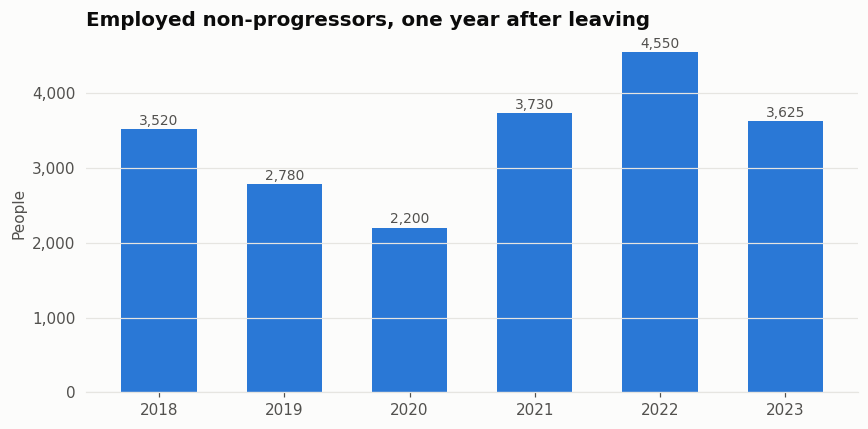

In [6]:
sizes = sel(years_since=1).set_index("cohort_year")["n"]
fig, ax = plt.subplots(figsize=(8, 4))
ax.bar(sizes.index, sizes.values, color=SERIES[0], width=0.6)
for x, v in sizes.items(): ax.text(x, v + 60, f"{v:,.0f}", ha="center", fontsize=9, color=INK2)
ax.set_title("Employed non-progressors, one year after leaving")
ax.set_ylabel("People"); ax.set_xticks(sizes.index)
ax.yaxis.set_major_formatter(mtick.StrMethodFormatter("{x:,.0f}"))
save(fig, "01_cohort_sizes")

The **2020** cohort (who left during COVID-19) is the smallest at 2,200; **2022** is the largest at 4,550.

## 3. Earnings trajectory after non-progression

cohort_year,2018,2019,2020,2021,2022,2023
years_since,,,,,,
1,350.0,315.0,365.0,390.0,410.0,430.0
2,345.0,390.0,410.0,435.0,465.0,NaN
3,430.0,440.0,470.0,500.0,NaN,NaN
4,490.0,510.0,540.0,NaN,NaN,NaN
5,555.0,580.0,NaN,NaN,NaN,NaN
6,615.0,NaN,NaN,NaN,NaN,NaN


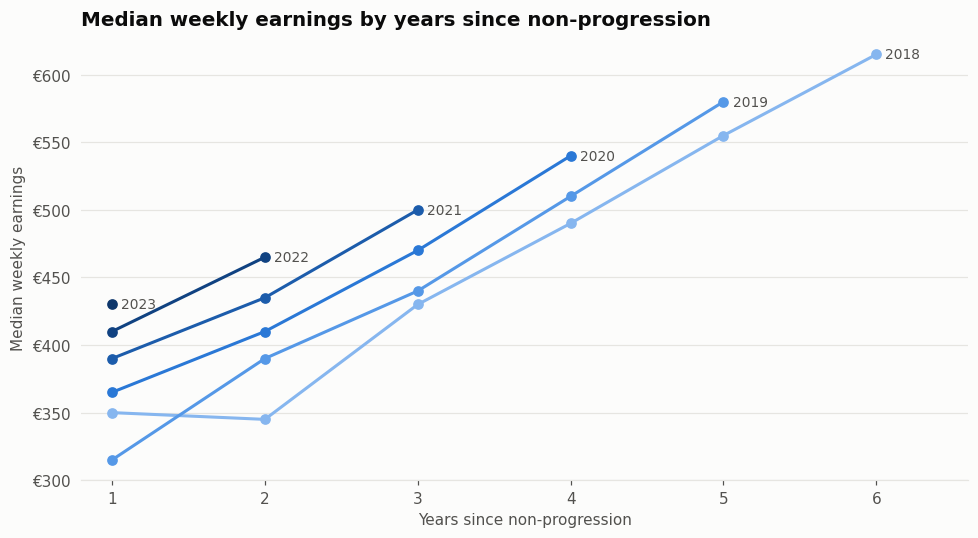

In [7]:
traj = sel().pivot_table(index="years_since", columns="cohort_year", values="p50")
fig, ax = plt.subplots()
for i, c in enumerate(traj.columns):
    s = traj[c].dropna()
    ax.plot(s.index, s.values, marker="o", color=BLUE_RAMP[i])
    label_end(ax, s.index[-1], s.values[-1], str(c))
ax.set_title("Median weekly earnings by years since non-progression")
ax.set_xlabel("Years since non-progression"); ax.set_ylabel("Median weekly earnings")
ax.yaxis.set_major_formatter(EUR); ax.set_xlim(0.8, 6.6)
save(fig, "02_trajectory_by_cohort")
traj

In [8]:
# Growth: year-1 to latest observed year, per cohort
g = traj.apply(lambda s: pd.Series({"year1": s.iloc[0], "latest": s.dropna().iloc[-1],
                                    "years": s.dropna().index[-1] - 1}))
g = g.T
g["total_growth"] = (g.latest / g.year1 - 1)
g["cagr"] = np.where(g.years > 0, (g.latest / g.year1) ** (1 / g.years.replace(0, np.nan)) - 1, np.nan)
g.style.format({"year1": "€{:.0f}", "latest": "€{:.0f}", "years": "{:.0f}",
                "total_growth": "{:.0%}", "cagr": "{:.1%}"})

,year1,latest,years,total_growth,cagr
cohort_year,,,,,
2018,€350,€615,5,76%,11.9%
2019,€315,€580,4,84%,16.5%
2020,€365,€540,3,48%,13.9%
2021,€390,€500,2,28%,13.2%
2022,€410,€465,1,13%,13.4%
2023,€430,€430,0,0%,nan%


- Earnings rise steadily: the 2018 cohort goes from **€350 → €615/week** nominal over six years (+76%, ~12% a year).
- Year-1 median rose from €350 (2018) to €430 (2023) in nominal terms — section 3b shows this is almost all inflation.
- The 2018 cohort is flat from year 1 to year 2 (€350 → €345): their second year was 2020, the year of COVID.

## 3b. Real terms (constant 2024 euro)

Nominal earnings are deflated with the CSO **Consumer Price Index, table CPA01** (annual average, All items),
using `earnings_year = cohort_year + years_since`: `real = nominal × CPI₂₀₂₄ / CPI_year` (see `src/cpi.py`).
Irish inflation was ~0–2% in 2019–2021, then **7.8% in 2022** and **6.3% in 2023**.

*Assumption:* "N years since non-progression" is taken to mean calendar year cohort + N. If the CSO defines the
reference year differently, the deflator shifts by a year — check the NPO release methodology.

CPI (Dec 2023 = 100), annual average:
 Year
2019     84.3
2020     84.0
2021     86.0
2022     92.7
2023     98.6
2024    100.7


,year1,latest,years,real_growth,real_cagr
cohort_year,,,,,
2018,€418,€615,5,47%,8.0%
2019,€378,€580,4,54%,11.3%
2020,€427,€540,3,26%,8.1%
2021,€424,€500,2,18%,8.6%
2022,€419,€465,1,11%,11.1%
2023,€430,€430,0,0%,–


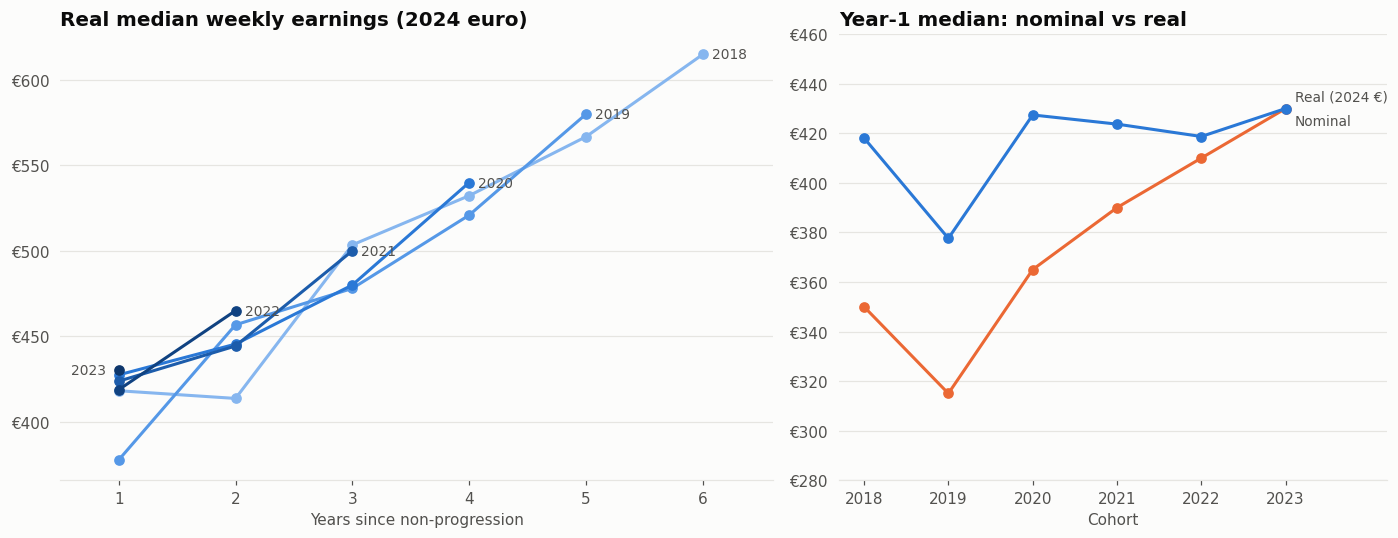

In [9]:
from cpi import load_cpi, BASE_YEAR
cpi = load_cpi()
print("CPI (Dec 2023 = 100), annual average:\n", cpi.loc[2019:2024].to_string())

traj_real = sel().pivot_table(index="years_since", columns="cohort_year", values="p50_real")
y1 = sel(years_since=1).set_index("cohort_year")[["p50", "p50_real"]]

fig, axes = plt.subplots(1, 2, figsize=(13, 5), gridspec_kw={"width_ratios": [1.3, 1]})
ax = axes[0]
for i, c in enumerate(traj_real.columns):
    s = traj_real[c].dropna()
    ax.plot(s.index, s.values, marker="o", color=BLUE_RAMP[i])
    if len(s) == 1:  # single point: label to the left so it doesn't sit on other lines
        ax.annotate(str(c), (s.index[0], s.values[0]), xytext=(-8, 0), textcoords="offset points",
                    ha="right", va="center", fontsize=9, color=INK2)
    else:
        label_end(ax, s.index[-1], s.values[-1], str(c))
ax.set_title(f"Real median weekly earnings ({BASE_YEAR} euro)")
ax.set_xlabel("Years since non-progression"); ax.yaxis.set_major_formatter(EUR); ax.set_xlim(0.5, 6.6)

ax = axes[1]
ax.plot(y1.index, y1.p50, marker="o", color=SERIES[1]); label_end(ax, 2023, y1.p50.iloc[-1], "Nominal", dy=-8)
ax.plot(y1.index, y1.p50_real, marker="o", color=SERIES[0]); label_end(ax, 2023, y1.p50_real.iloc[-1], f"Real ({BASE_YEAR} €)", dy=8)
ax.set_title("Year-1 median: nominal vs real"); ax.set_xlabel("Cohort")
ax.yaxis.set_major_formatter(EUR); ax.set_xticks(y1.index); ax.set_xlim(2017.7, 2024.2); ax.set_ylim(280, 460)
save(fig, "02b_real_terms")

g_real = traj_real.apply(lambda s: pd.Series({"year1": s.iloc[0], "latest": s.dropna().iloc[-1],
                                              "years": s.dropna().index[-1] - 1})).T
g_real["real_growth"] = g_real.latest / g_real.year1 - 1
g_real["real_cagr"] = np.where(g_real.years > 0,
                               (g_real.latest / g_real.year1) ** (1 / g_real.years.clip(lower=1)) - 1, np.nan)
g_real.style.format({"year1": "€{:.0f}", "latest": "€{:.0f}", "years": "{:.0f}",
                     "real_growth": "{:.0%}", "real_cagr": "{:.1%}"}, na_rep="–")

- **Starting pay hasn't risen in real terms.** Year-1 median is **≈€420–430 in 2024 euro for every cohort** except 2019 (€378).
  The nominal climb from €350 to €430 was almost entirely inflation.
- **Career growth is real but slower:** the 2018 cohort goes €418 → €615 in 2024 euro (+47%, ≈8% a year) versus +76% nominal.
- The 2022–2023 inflation spike flattened real growth: e.g. the 2019 cohort's real pay barely moved from year 2 to year 3 (€457 → €478).

### Earnings spread (25th–75th percentile), 2018 cohort

,p25,p50,p75,iqr
years_since,,,,
1,265.0,350.0,430.0,165.0
2,250.0,345.0,450.0,200.0
3,335.0,430.0,535.0,200.0
4,370.0,490.0,610.0,240.0
5,430.0,555.0,695.0,265.0
6,495.0,615.0,780.0,285.0


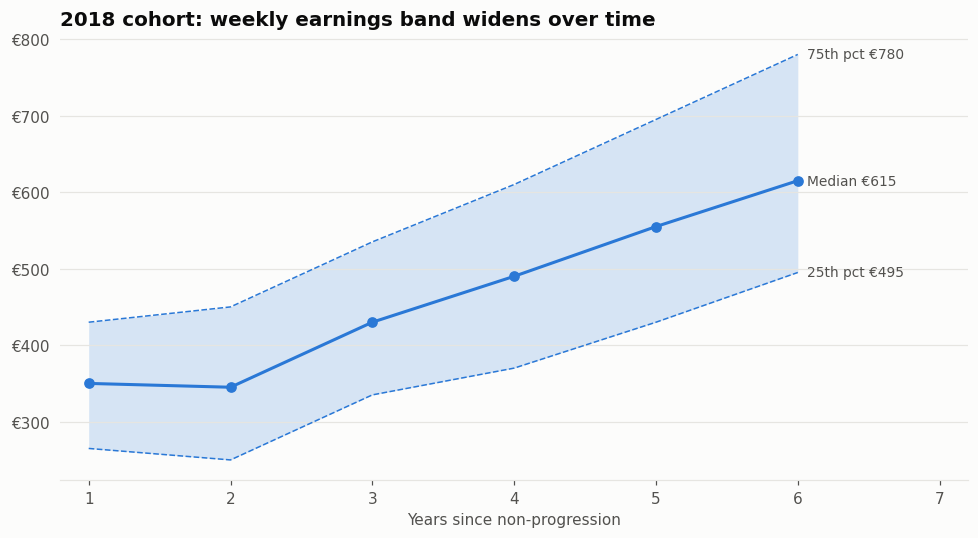

In [10]:
b = sel(cohort_year=2018).set_index("years_since")[["p25", "p50", "p75"]]
fig, ax = plt.subplots()
ax.fill_between(b.index, b.p25, b.p75, color=SERIES[0], alpha=0.18, linewidth=0)
ax.plot(b.index, b.p50, marker="o", color=SERIES[0])
for col, lab in [("p75", "75th pct"), ("p50", "Median"), ("p25", "25th pct")]:
    label_end(ax, 6, b[col].iloc[-1], f"{lab} €{b[col].iloc[-1]:.0f}")
ax.plot(b.index, b.p25, color=SERIES[0], lw=1, ls="--"); ax.plot(b.index, b.p75, color=SERIES[0], lw=1, ls="--")
ax.set_title("2018 cohort: weekly earnings band widens over time")
ax.set_xlabel("Years since non-progression"); ax.yaxis.set_major_formatter(EUR); ax.set_xlim(0.8, 7.2)
save(fig, "03_band_2018")
b.assign(iqr=b.p75 - b.p25)

## 4. Gender gap

gender                   Female   Male  gap_eur  gap_pct
cohort_year years_since                                 
2018        1             330.0  365.0     35.0    0.096
            2             310.0  370.0     60.0    0.162
            3             400.0  455.0     55.0    0.121
            4             460.0  515.0     55.0    0.107
            5             530.0  580.0     50.0    0.086
            6             580.0  645.0     65.0    0.101
2019        1             290.0  330.0     40.0    0.121
            2             365.0  405.0     40.0    0.099
            3             410.0  455.0     45.0    0.099
            4             475.0  535.0     60.0    0.112
            5             550.0  605.0     55.0    0.091
2020        1             355.0  370.0     15.0    0.041
            2             400.0  420.0     20.0    0.048
            3             455.0  480.0     25.0    0.052
            4             510.0  555.0     45.0    0.081
2021        1             375.0  400.0     25.0    0.062
            2             410.0  450.0     40.0    0.089
            3             470.0  520.0     50.0    0.096
2022        1             390.0  425.0     35.0    0.082
            2             445.0  480.0     35.0    0.073
2023        1             415.0  440.0     25.0    0.057

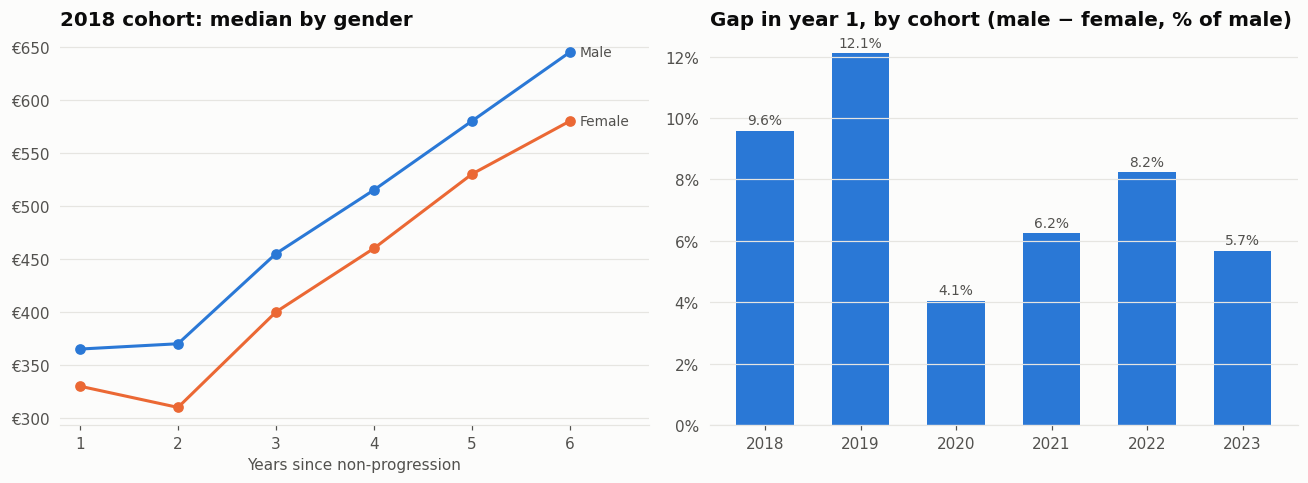

In [11]:
gg = sel(gender=["Male", "Female"]).pivot_table(index=["cohort_year", "years_since"], columns="gender",
                                               values="p50", observed=True)
gg["gap_eur"] = gg.Male - gg.Female
gg["gap_pct"] = gg.gap_eur / gg.Male
gap_y1 = gg.xs(1, level="years_since")
gap_2018 = gg.xs(2018, level="cohort_year")

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
ax = axes[0]
for i, gname in enumerate(["Male", "Female"]):
    ax.plot(gap_2018.index, gap_2018[gname], marker="o", color=SERIES[i])
    label_end(ax, 6, gap_2018[gname].iloc[-1], gname)
ax.set_title("2018 cohort: median by gender"); ax.set_xlabel("Years since non-progression")
ax.yaxis.set_major_formatter(EUR); ax.set_xlim(0.8, 6.8)

ax = axes[1]
ax.bar(gap_y1.index, gap_y1.gap_pct, color=SERIES[0], width=0.6)
for x, v in gap_y1.gap_pct.items(): ax.text(x, v + 0.002, f"{v:.1%}", ha="center", fontsize=9, color=INK2)
ax.set_title("Gap in year 1, by cohort (male − female, % of male)")
ax.yaxis.set_major_formatter(mtick.PercentFormatter(1, decimals=0)); ax.set_xticks(gap_y1.index)
save(fig, "04_gender_gap")
gg.round(3)

- Men's median is higher in every cohort. In year 1 the gap ranges from **4.1% (2020) to 12.1% (2019)**.
- For the 2018 cohort the euro gap stays roughly flat (€35–65/week) while pay rises, so the **% gap shrinks** over time.
- The gap may partly reflect **sector mix** (e.g. Construction is male-dominated and pays well) — see section 6.

## 5. NFQ level of the course they left

nfq_level,NFQ Level 6,NFQ Level 7,NFQ Level 8
years_since,,,
1,350.0,360.0,345.0
2,360.0,350.0,340.0
3,425.0,445.0,425.0
4,475.0,505.0,485.0
5,520.0,560.0,555.0
6,595.0,605.0,625.0


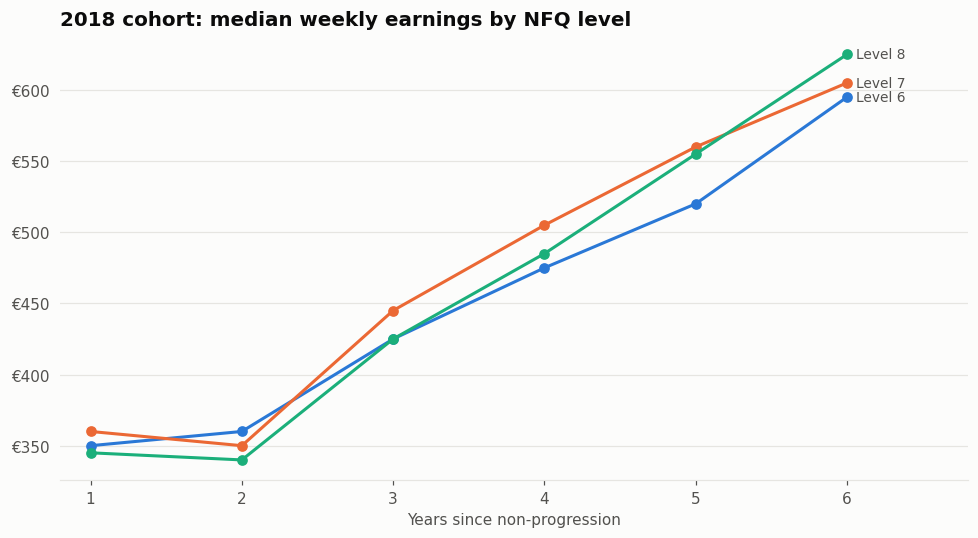

In [12]:
lv = sel(nfq_level=["NFQ Level 6", "NFQ Level 7", "NFQ Level 8"], cohort_year=2018) \
       .pivot_table(index="years_since", columns="nfq_level", values="p50", observed=True)
fig, ax = plt.subplots()
for i, c in enumerate(lv.columns):
    ax.plot(lv.index, lv[c], marker="o", color=SERIES[i])
    label_end(ax, 6, lv[c].iloc[-1], c.replace("NFQ ", ""))
ax.set_title("2018 cohort: median weekly earnings by NFQ level")
ax.set_xlabel("Years since non-progression"); ax.yaxis.set_major_formatter(EUR); ax.set_xlim(0.8, 6.8)
save(fig, "05_nfq_level")
lv

In [13]:
# Year-1 medians across all cohorts
sel(nfq_level=["NFQ Level 6", "NFQ Level 7", "NFQ Level 8"], years_since=1) \
    .pivot_table(index="cohort_year", columns="nfq_level", values="p50", observed=True)

nfq_level,NFQ Level 6,NFQ Level 7,NFQ Level 8
cohort_year,,,
2018,350.0,360.0,345.0
2019,310.0,330.0,310.0
2020,365.0,370.0,365.0
2021,395.0,405.0,385.0
2022,430.0,420.0,405.0
2023,425.0,435.0,425.0


## 6. Sector of employment
Dumbbell: year-1 vs year-6 median, 2018 cohort (the only cohort with six years of data).

,year1,year6,growth
sector,,,
Construction (F),€345,€760,120%
Public Administration and Defence (O),€460,€740,61%
Information and communication (J),€420,€735,75%
Transportation & Storage (H),€410,€705,72%
Industry (B to E),€440,€685,56%
"Financial & Real Estate (K,L)",€365,€655,79%
"Professional, Scientific and Technical Activities (M)",€400,€635,59%
Education (P),€265,€615,132%
Human Health and Social Work Activities (Q),€365,€610,67%


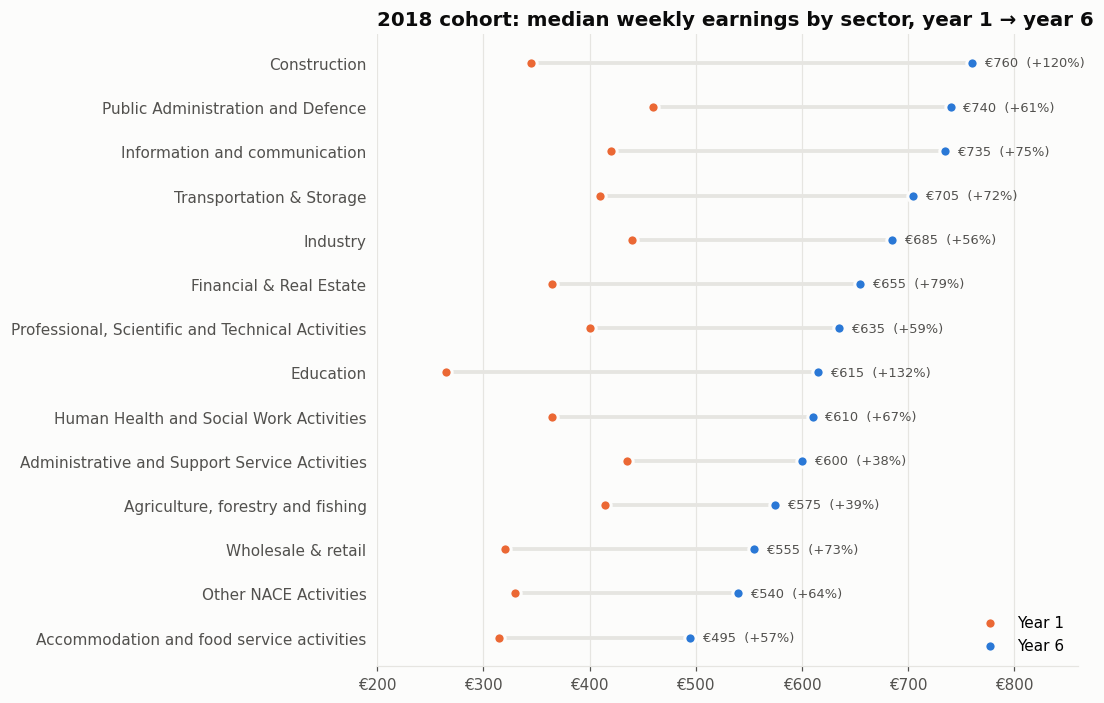

In [14]:
sec = sel(sector=None, cohort_year=2018).query("sector not in ['All sectors', 'Unknown']") \
        .pivot_table(index="sector", columns="years_since", values="p50", observed=True)[[1, 6]]
sec.columns = ["year1", "year6"]
sec["growth"] = sec.year6 / sec.year1 - 1
sec = sec.sort_values("year6")
short = lambda s: s.split(" (")[0].replace("Wholesale and retail trade; repair of motor vehicles and motorcycles", "Wholesale & retail")

fig, ax = plt.subplots(figsize=(10, 6.5))
y = np.arange(len(sec))
ax.hlines(y, sec.year1, sec.year6, color=GRID, lw=2.5)
ax.scatter(sec.year1, y, color=SERIES[1], s=55, zorder=3, edgecolor=SURFACE, linewidth=2, label="Year 1")
ax.scatter(sec.year6, y, color=SERIES[0], s=55, zorder=3, edgecolor=SURFACE, linewidth=2, label="Year 6")
for yi, (_, r) in zip(y, sec.iterrows()):
    ax.text(r.year6 + 12, yi, f"€{r.year6:.0f}  (+{r.growth:.0%})", va="center", fontsize=8.5, color=INK2)
ax.set_yticks(y, [short(s) for s in sec.index])
ax.grid(axis="x", color=GRID); ax.grid(axis="y", visible=False)
ax.xaxis.set_major_formatter(EUR); ax.set_xlim(200, 860)
ax.set_title("2018 cohort: median weekly earnings by sector, year 1 → year 6")
ax.legend(loc="lower right")
save(fig, "06_sector_dumbbell")
sec.sort_values("year6", ascending=False).style.format({"year1": "€{:.0f}", "year6": "€{:.0f}", "growth": "{:.0%}"})

In [15]:
# Where do they work? Share of employed non-progressors by sector (year 1, latest cohort)
share = sel(sector=None, cohort_year=2023, years_since=1).query("sector != 'All sectors'") \
          .set_index("sector")["n"].sort_values(ascending=False)
(share / share.sum()).map("{:.1%}".format).rename("share").to_frame()

,share
sector,
Wholesale and retail trade; repair of motor vehicles and motorcycles (G),32.1%
Accommodation and food service activities (I),21.2%
Construction (F),8.1%
Administrative and Support Service Activities (N),7.4%
Industry (B to E),7.2%
Human Health and Social Work Activities (Q),4.8%
Other NACE Activities (R - U),4.6%
"Professional, Scientific and Technical Activities (M)",3.9%
Transportation & Storage (H),2.6%


- **Highest by year 6:** Construction, Public Administration and ICT (≈€735–760/week).
- **Fastest growth:** Construction more than doubles (+120%), Education +132% from a low base (many are part-time early on).
- **Lowest:** Accommodation & Food, Wholesale & Retail and Other activities — also the biggest employers of
  recent non-progressors (see share table), which pulls the overall median down.

## 7. Employment only vs employment plus further education

outcome,Employment and Education,Employment only
years_since,,
1,305.0,370.0
2,290.0,370.0
3,380.0,460.0
4,455.0,510.0
5,540.0,560.0
6,610.0,620.0


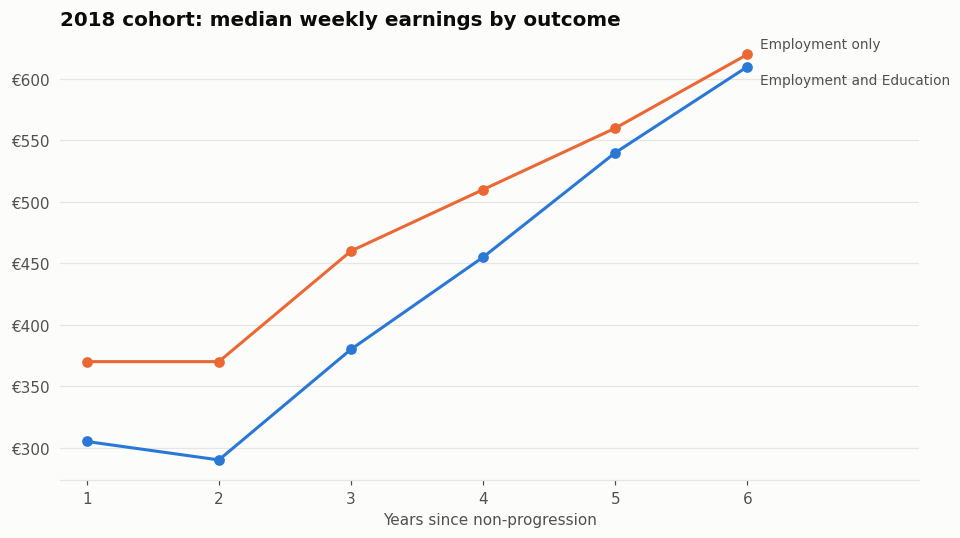

In [16]:
oc = sel(outcome=["Employment only", "Employment and Education"], cohort_year=2018) \
       .pivot_table(index="years_since", columns="outcome", values="p50", observed=True)
fig, ax = plt.subplots()
for i, c in enumerate(oc.columns):
    ax.plot(oc.index, oc[c], marker="o", color=SERIES[i])
    ax.annotate(c, (6, oc[c].iloc[-1]), xytext=(8, -9 if c == "Employment and Education" else 7),
                textcoords="offset points", va="center", fontsize=9, color=INK2)
ax.set_title("2018 cohort: median weekly earnings by outcome")
ax.set_xlabel("Years since non-progression"); ax.yaxis.set_major_formatter(EUR)
ax.set_xlim(0.8, 7.3); ax.set_xticks(range(1, 7))
save(fig, "07_outcome")
oc

People combining work with education earn much less early on (€305 vs €370 in year 1, often part-time / student jobs), but the gap **almost closes by year 6** (€610 vs €620) as some of them finish a qualification.

## 8. Heatmap: median by cohort × years since (all dimensions)

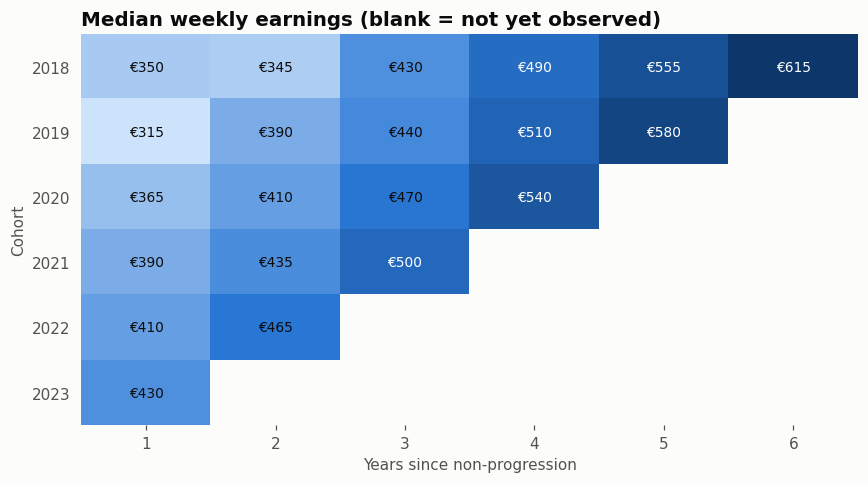

In [17]:
fig, ax = plt.subplots(figsize=(8, 4.5))
cmap = plt.matplotlib.colors.LinearSegmentedColormap.from_list("blue", ["#cde2fb", "#2a78d6", "#0d366b"])
im = ax.imshow(grid.values, cmap=cmap, aspect="auto")
ax.set_xticks(range(grid.shape[1]), grid.columns); ax.set_yticks(range(grid.shape[0]), grid.index)
for i in range(grid.shape[0]):
    for j in range(grid.shape[1]):
        v = grid.values[i, j]
        if not np.isnan(v):
            ax.text(j, i, f"€{v:.0f}", ha="center", va="center", fontsize=9,
                    color="white" if v > 470 else INK)
ax.grid(False); ax.set_xlabel("Years since non-progression"); ax.set_ylabel("Cohort")
ax.set_title("Median weekly earnings (blank = not yet observed)")
for s in ax.spines.values(): s.set_visible(False)
save(fig, "08_heatmap")

## Summary

| Finding | Evidence |
|---|---|
| Earnings grow ~8%/yr in real terms after non-progression | 2018 cohort €418 → €615 (2024 euro); +76% nominal |
| Starting pay is flat in real terms | Year-1 median ≈ €420–430 (2024 euro) for every cohort except 2019; nominal rise is inflation |
| COVID dented early careers | 2018 cohort flat in year 2 (2020); 2020 cohort smallest |
| Persistent gender gap | Male median above female in every cohort (year 1: 4–12%) |
| Sector is a major driver | Year 6: Construction/ICT/Public Admin ≈ €735–760 vs Hospitality €495 |
| Studying while working costs early, catches up later | 2018 cohort: €65 gap in year 1 → €10 by year 6 |

**Caveats:** sections other than 3b use nominal euro (gaps and rankings within one year are unaffected by CPI);
counts and earnings rounded to 5; percentiles can't be averaged across groups; weekly earnings mix full- and part-time work;
real figures assume earnings year = cohort + years since.

**Next steps**
- Compare with graduate earnings (CSO Higher Education Outcomes tables) to size the non-progression "penalty".
- Model p50 on gender × NFQ × sector × years to separate sector-mix effects from the gender gap.
- Interactive dashboard on top of `data/processed/npo13_tidy.parquet` (has `*_real` columns).